## Import Required Libraries

In [1]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.integrate import odeint
from scipy.interpolate import pchip_interpolate
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import spsolve
from scipy.integrate import trapz
from math import atan2, pi, sin, cos, sqrt, exp
import warnings
import deepxde as dde

dde.backend.set_default_backend("pytorch")
warnings.filterwarnings('ignore')

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


Setting the default backend to "pytorch". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)


## System Parameters Setup

In [2]:
class Struct:
    pass

# System parameters (from paper Section 5)
sys = Struct()
sys.ctrl_on = 1  # control on/off switch

# Parameters from the paper
lam_val = 1.0     # lambda(x) = 1
mu_val = 2.0      # mu(x) = 2
q_val = 1.2       # q = 1.2
rho_val = 0.3     # rho = 0.3

# Event-triggered parameters
R_L = 0.1     # Lyapunov-based parameter
zeta = 1.5        # zeta parameter
nu_param = 1.2    # nu parameter

# Simulation parameters
sys.L = 1.0       # spatial domain [0, 1]
sys.T = 15.0      # simulation time 15 s
sys.N = 100       # number of interior spatial points
sys.N_grid = sys.N + 2
sys.N_g = 100     # number of grid points to solve kernels
sys.h = 0.01    # time step
sys.Tspan = np.arange(0, sys.T + sys.h, sys.h)
sys.Delta = sys.L / (sys.N + 1)
sys.xspan = np.linspace(0, sys.L, sys.N_grid)
sys.xspanT = sys.xspan[1:-1]  # drop boundaries, length N
sys.xspan_g = np.linspace(0, sys.L, sys.N_g)  # grid for kernel computation

print(f"Spatial step: {sys.Delta:.4f}")
print(f"Time step: {sys.h:.4f}")
print(f"Grid points (interior N): {sys.N}")
print(f"Grid points for kernels (N_g): {sys.N_g}")
print(f"Simulation horizon: {sys.T}s")


Spatial step: 0.0099
Time step: 0.0100
Grid points (interior N): 100
Grid points for kernels (N_g): 100
Simulation horizon: 15.0s


## System Parameter Functions and Coupling Coefficients

In [3]:
# System parameter functions
fun = Struct()
fun.lam = lambda x: lam_val * np.ones_like(x)  # λ(x) = 1
fun.mu = lambda x: mu_val * np.ones_like(x)    # μ(x) = 2
fun.q = q_val                                   # q = 1.2
fun.rho = rho_val                               # ρ = 0.3
fun.lam_d = lambda x: 0.0 * np.ones_like(x)  # dλ/dx = 0
fun.mu_d = lambda x: 0.0 * np.ones_like(x)   # dμ/dx = 0

# Time- and space-varying coupling coefficients σ+(t,x) and σ-(t,x)
def sigma_plus(t, x):
    """σ+(t,x) = 1 + 0.3*x*exp(2*sin²(t))"""
    return 1 + 0.3 * x * np.exp(2.0*(np.sin(t))**2)


def sigma_minus(t, x):
    """σ-(t,x) = 1 + 0.3*x*exp(2*cos²(t))"""
    return 1.0 + 2.0/((np.cosh((t-7)**2))**2) + 0.6*np.cos(np.pi*t) + 2.0/((np.cosh(5*x))**2)

print("Coupling coefficient functions defined")




Coupling coefficient functions defined


## Load Pre-trained Neural Operator (or use dummy for initialization)

In [4]:
# Load training data generated from all-kernel dataset
import os

# Check if training and validation data exist
train_files = {
    "X_train": "X_train_allkernels.npy",
    "Y_train": "Y_train_allkernels.npy",
    "X_val": "X_val_allkernels.npy",
    "Y_val": "Y_val_allkernels.npy"
}

training_data_available = all(os.path.exists(f) for f in train_files.values())

if training_data_available:
    print("Found training data files!")
    
    # Load the data
    X_train = np.load(train_files["X_train"])
    Y_train = np.load(train_files["Y_train"])
    X_val = np.load(train_files["X_val"])
    Y_val = np.load(train_files["Y_val"])
    
    print(f"\nTraining Data Summary:")
    print(f"  X_train shape: {X_train.shape}")
    print(f"  Y_train shape: {Y_train.shape}")
    print(f"  X_val shape: {X_val.shape}")
    print(f"  Y_val shape: {Y_val.shape}")
    
    # Check data statistics
    print(f"\nTraining Data Statistics:")
    print(f"  X_train: mean={X_train.mean():.6f}, std={X_train.std():.6f}")
    print(f"  Y_train: mean={Y_train.mean():.6f}, std={Y_train.std():.6f}")
    
    # Determine if we should train based on user configuration
    TRAIN_MODEL_IF_NO_DATA = False
    should_train = TRAIN_MODEL_IF_NO_DATA
    
    if should_train:
        print(f"\n✓ TRAIN_MODEL_IF_NO_DATA = {TRAIN_MODEL_IF_NO_DATA}")
        print("  Training will be performed in next cell.")
    else:
        print(f"\n✗ TRAIN_MODEL_IF_NO_DATA = {TRAIN_MODEL_IF_NO_DATA}")
        print("  Training will be SKIPPED.")
        print("  The model will load pre-trained weights if available")
        print("  Otherwise, will use exact kernel solver.")
    
    # # Prepare DataLoader for training
    batch_size = 32
    X_train_tensor = torch.from_numpy(X_train.astype(np.float32))
    Y_train_tensor = torch.from_numpy(Y_train.astype(np.float32))
    X_val_tensor = torch.from_numpy(X_val.astype(np.float32))
    Y_val_tensor = torch.from_numpy(Y_val.astype(np.float32))
    
    train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
    val_dataset = TensorDataset(X_val_tensor, Y_val_tensor)
    
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    print(f"\nDataLoader Configuration:")
    print(f"  Batch size: {batch_size}")
    print(f"  Training batches: {len(train_loader)}")
    print(f"  Validation batches: {len(val_loader)}")
    
else:
    print("Training data files not found!")
    print("  X_train_allkernels.npy")
    print("  Y_train_allkernels.npy")
    print("  X_val_allkernels.npy")
    print("  Y_val_allkernels.npy")
    print("\nTo generate training data, run: ETC_NO_TrainData_AllKernels.ipynb")
    print("\nProceeding without training data...")
    should_train = False

Found training data files!

Training Data Summary:
  X_train shape: (1600, 200)
  Y_train shape: (1600, 20200)
  X_val shape: (400, 200)
  Y_val shape: (400, 20200)

Training Data Statistics:
  X_train: mean=1.585436, std=0.754384
  Y_train: mean=-0.298337, std=0.607660

✗ TRAIN_MODEL_IF_NO_DATA = False
  Training will be SKIPPED.
  The model will load pre-trained weights if available
  Otherwise, will use exact kernel solver.

DataLoader Configuration:
  Batch size: 32
  Training batches: 50
  Validation batches: 13


## ODE Dynamics with Backstepping Kernels


In [5]:
def ode_dynamic_etc(x, t, sys, current_Kvu, current_Kvv,current_Kuu, current_Kuv):
    """
    ODE dynamics using the current frozen kernels at the latest event.
    """
    N = sys.N
    N_grid = sys.N_grid
    
    dummy = np.reshape(x[0:2*N], (N, 2), order='F')
    # ghost points for boundary conditions (linear extrapolation)
    dummy_a = np.vstack([2*dummy[0, :] - dummy[1, :], dummy, 2*dummy[N-1, :] - dummy[N-2, :]])

    u_sf_a = dummy_a[:, 0]
    u_sf = u_sf_a[1:N+1]
    v_sf_a = dummy_a[:, 1]
    v_sf = v_sf_a[1:N+1]

    # Boundary control input (using frozen kernels)
    if sys.ctrl_on == 1:
        # interpolate kernels to current spatial grid and integrate
        Kuu_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kuu[:, -1], sys.xspan)
        Kuv_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kuv[:, -1], sys.xspan)
        Kvu_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kvu[:, -1], sys.xspan)
        Kvv_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kvv[:, -1], sys.xspan)
        
        U_sf = trapz((Kvu_interp- rho_val*Kuu_interp) * u_sf_a, sys.xspan) + trapz((Kvv_interp-rho_val*Kuv_interp) * v_sf_a, sys.xspan)
    else:
        U_sf = 0
    
    # Boundary conditions
    u_sf_a[0] = fun.q * v_sf_a[0]
    v_sf_a[N_grid - 1] = fun.rho * u_sf_a[N_grid - 1] + U_sf

    # Spatial derivatives (upwind-like one-sided and interior formulas)
    u_sf_x = np.hstack([(u_sf_a[1] - u_sf_a[0]) / sys.Delta,
                        (u_sf_a[0:(N_grid - 3)] - 4 * u_sf_a[1:(N_grid - 2)] + 3 * u_sf_a[2:(N_grid - 1)]) / (2 * sys.Delta)])
    v_sf_x = np.hstack([(-3 * v_sf_a[1:(N_grid - 2)] + 4 * v_sf_a[2:(N_grid - 1)] - v_sf_a[3:N_grid]) / (2 * sys.Delta),
                         (v_sf_a[N_grid - 1] - v_sf_a[N_grid - 2]) / sys.Delta])

    # PDE dynamics (use real-time time-varying coefficients)
    lam_vals = fun.lam(sys.xspanT)
    mu_vals = fun.mu(sys.xspanT)
    sigma_plus_vals = sigma_plus(t, sys.xspanT)
    sigma_minus_vals = sigma_minus(t, sys.xspanT)
    
    u_sf_t = -lam_vals * u_sf_x + sigma_plus_vals * v_sf
    v_sf_t = mu_vals * v_sf_x + sigma_minus_vals * u_sf

    dt = np.hstack([u_sf_t, v_sf_t])
    return dt

print("ODE dynamics function defined")

ODE dynamics function defined


## Train Neural Operator

In [6]:
# Network dimensions for DeepONet
dim_x = 1                 # trunk input: coordinate dimension
num_outputs = 20200       # target number of output points (4 kernels * 5050 each)
m = 200                   # branch input dimension (sigma+ and sigma- concatenated)
p = 256                   # aligned output dimension for branch and trunk
activation = "relu"
kernel = "Glorot normal"

# DeepONet architecture with aligned branch/trunk outputs
branch = [m, 256, 256, p]        # branch: (B,200) -> (B,256)
trunk = [dim_x, 256, 256, p]     # trunk:  (B*N,1) -> (B*N,256)

# Initialize DeepONet
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_no = dde.nn.DeepONet(branch, trunk, activation, kernel)
model_no = model_no.to(device)

# Prepare trunk coordinates for all output points
# For inference: we'll evaluate at these fixed coordinates
trunk_coords_np = np.linspace(0, 1, num_outputs).reshape(-1, 1).astype(np.float32)  # (20200, 1)
trunk_coords = torch.from_numpy(trunk_coords_np).to(device)

# Count parameters
total_params = sum(p.numel() for p in model_no.parameters())
print(f"Device: {device}")
print(f"DeepONet Architecture:")
print(f"  Branch net: {m} -> 256 -> 256 -> {p}")
print(f"  Trunk net:  {dim_x} -> 256 -> 256 -> {p}")
print(f"  Output: dot product -> scalar per evaluation point")
print(f"  Evaluation points: {num_outputs}")
print(f"Total parameters: {total_params:,}")

Device: cuda
DeepONet Architecture:
  Branch net: 200 -> 256 -> 256 -> 256
  Trunk net:  1 -> 256 -> 256 -> 256
  Output: dot product -> scalar per evaluation point
  Evaluation points: 20200
Total parameters: 315,137


In [7]:
# Test DeepONet inference with batch processing
B = 32  # batch size

# Define batch inference function (will be used during training)
def deeponet_batch_inference(model, branch_batch, trunk_coords):
    """
    Evaluate DeepONet for a batch of samples at multiple trunk points.
    
    Args:
        model: DeepONet model
        branch_batch: (B, m) branch inputs
        trunk_coords: (N, 1) trunk evaluation coordinates
    
    Returns:
        outputs: (B, N) - each sample evaluated at N points
    """
    B = branch_batch.shape[0]
    N = trunk_coords.shape[0]
    
    outputs = []
    for i in range(B):
        # Single sample
        branch_single = branch_batch[i:i+1]  # (1, m)
        # Repeat for all trunk points
        branch_repeated = branch_single.repeat(N, 1)  # (N, m)
        # Forward pass
        output = model((branch_repeated, trunk_coords))  # (N, 1) or (N,)
        if output.dim() > 1:
            output = output.squeeze(-1)  # (N,)
        outputs.append(output)
    
    return torch.stack(outputs, dim=0)  # (B, N)

# Test with random input
print(f"Testing DeepONet with batch_size={B}, num_outputs={num_outputs}")
input_branch_batch = torch.randn(B, 200, dtype=torch.float32).to(device)
output_batch = deeponet_batch_inference(model_no, input_branch_batch, trunk_coords)
print(f"  Input: {input_branch_batch.shape}")
print(f"  Output: {output_batch.shape}")
print(f"  Expected: torch.Size([{B}, {num_outputs}])")
print(f"✓ DeepONet batch inference works correctly!")

Testing DeepONet with batch_size=32, num_outputs=20200
  Input: torch.Size([32, 200])
  Output: torch.Size([32, 20200])
  Expected: torch.Size([32, 20200])
✓ DeepONet batch inference works correctly!


## Load model

In [8]:
# Check if trained model exists
import os

model_path = 'neural_operator_etc_model.pt'

model_loaded = True if os.path.exists(model_path) else False

# Try to load pre-trained model

if model_loaded:
    try:
        model_no.load_state_dict(torch.load(model_path, map_location=device))
        print(f"\nPre-trained model loaded from {model_path}")
    except Exception as e:
        print(f"✗ Failed to load pre-trained model: {e}")
        print("  Will initialize with random weights (train first!)")
else:
    print(f"\nNo pre-trained model found at {model_path}")
    print("Will initialize with random weights (train first!)")

# Set to evaluation mode
model_no.eval()


Pre-trained model loaded from neural_operator_etc_model.pt


DeepONet(
  (branch): FNN(
    (linears): ModuleList(
      (0): Linear(in_features=200, out_features=256, bias=True)
      (1-2): 2 x Linear(in_features=256, out_features=256, bias=True)
    )
  )
  (trunk): FNN(
    (linears): ModuleList(
      (0): Linear(in_features=1, out_features=256, bias=True)
      (1-2): 2 x Linear(in_features=256, out_features=256, bias=True)
    )
  )
)

## Kernel Solver (for reference/validation)

In [9]:
def solver_2x2(params, N_g):
    """Solve the backstepping kernels K and L on the triangular domain."""
    Delta = 1 / (N_g - 1)
    numTot = int(N_g*(N_g + 1) / 2)

    # Map lower-triangular indices to global indices
    index_map = np.zeros((N_g, N_g))
    index_map[np.tril_indices(N_g)] = np.arange(1, numTot+1)
    index_map = np.transpose(index_map)

    dummy1 = np.tril(np.reshape(np.arange(1, (N_g**2)+1), (N_g, N_g))).transpose()
    glob_to_mat = dummy1[dummy1 > 0]
    glob_to_mat = np.array(sorted(glob_to_mat))

    indexes = np.kron(np.arange(1, (2*numTot)+1), np.ones(5)).reshape((2*numTot,5)).astype(int)
    indexes = indexes - 1
    weights = np.zeros((2*numTot, 5))
    RHS = np.zeros((2*numTot, 1))

    # Directional derivatives (characteristics)
    s_K_x, s_K_y = np.meshgrid(params.mu, -params.lam)
    s_L_x, s_L_y = np.meshgrid(params.mu, params.mu)

    s_K = np.sqrt(s_K_x**2 + s_K_y**2)
    s_L = np.sqrt(s_L_x**2 + s_L_y**2)

    # K: iterate over triangular region
    for indX in range(N_g):
        for indY in range(indX+1):
            glob_ind = int(index_map[indY, indX])
            if (indY == indX):
                weights[glob_ind-1, 0] = 1
                RHS[glob_ind-1] = params.f[indY]
            else:
                theta = np.arctan2(s_K_x[indY, indX], -s_K_y[indY, indX])
                if theta > np.pi / 4:
                    sigma = Delta / np.sin(theta)
                    d = sigma * np.cos(theta)
                    preFactor = (s_K[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * d / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY + 1, indX - 1])-1
                    weights[glob_ind-1, 2] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY, indX - 1])-1
                else:
                    sigma = Delta / np.cos(theta)
                    d = sigma * np.sin(theta)
                    preFactor = (s_K[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * d / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY + 1, indX - 1])-1
                    weights[glob_ind-1, 2] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY + 1, indX])-1

                if indY == indX - 1:
                    if theta > np.pi / 4:
                        weights[glob_ind-1, 2] = weights[glob_ind-1, 2] + weights[glob_ind-1, 1]
                        weights[glob_ind-1, 0] = weights[glob_ind-1, 0] - weights[glob_ind-1, 1]
                        indexes[glob_ind-1, 1] = int(index_map[indY + 1, indX])-1
                    else:
                        weights[glob_ind-1, 2] = weights[glob_ind-1, 2] + weights[glob_ind-1, 1]
                        weights[glob_ind-1, 0] = weights[glob_ind-1, 0] - weights[glob_ind-1, 1]
                        indexes[glob_ind-1, 1] = int(index_map[indY, indX - 1])-1
    
    # L: iterate over triangular region
    for indX in range(N_g):
        for indY in range(indX + 1):
            glob_ind = int(index_map[indY, indX]) + numTot
            if indY == 0:
                weights[glob_ind-1, 0] = -1
                weights[glob_ind-1, 1] = params.q
                indexes[glob_ind-1, 1] = glob_ind - numTot - 1
            else:
                theta = np.arctan2(s_L_y[indY, indX], s_L_x[indY, indX])
                if theta < np.pi / 4:
                    sigma = Delta / np.cos(theta)
                    d = sigma * np.sin(theta)
                    preFactor = (s_L[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY, indX - 1]) + numTot - 1
                    weights[glob_ind-1, 2] = -preFactor * d / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY - 1, indX - 1]) + numTot - 1
                else:
                    sigma = Delta / np.sin(theta)
                    d = sigma * np.cos(theta)
                    preFactor = (s_L[indY, indX] / sigma)
                    weights[glob_ind-1, 0] = preFactor
                    weights[glob_ind-1, 1] = -preFactor * d / Delta
                    indexes[glob_ind-1, 1] = int(index_map[indY - 1, indX - 1]) + numTot - 1
                    weights[glob_ind-1, 2] = -preFactor * (Delta - d) / Delta
                    indexes[glob_ind-1, 2] = int(index_map[indY - 1, indX]) + numTot - 1

    # Source terms coupling K and L blocks
    for indX in range(N_g):
        for indY in range(indX+1):
            glob_ind = int(index_map[indY, indX])
            if indY != indX:
                weights[glob_ind-1, 3] = -params.a_1[indY, indX]
                weights[glob_ind-1, 4] = -params.a_2[indY, indX]
                indexes[glob_ind-1, 4] = glob_ind + numTot - 1

            if indY != 0:
                weights[glob_ind-1+numTot, 3] = -params.b_1[indY, indX]
                indexes[glob_ind-1+numTot, 3] = glob_ind - 1
                weights[glob_ind-1+numTot, 4] = -params.b_2[indY, indX]

    # Assemble sparse system and solve
    counter = 0
    A_coord_x = np.zeros(2*numTot * 5, dtype=int)
    A_coord_y = np.zeros(2*numTot * 5, dtype=int)
    A_vals = np.zeros(2*numTot * 5)
    b_coord_y = np.zeros(2*numTot, dtype=int)
    b_vals = np.zeros(2*numTot)

    for i in range(2*numTot):
        for j in range(5):
            A_coord_y[counter] = i
            A_coord_x[counter] = indexes[i, j]
            A_vals[counter] = weights[i, j]
            counter += 1
        b_coord_y[i] = i
        b_vals[i] = RHS[i][0]

    A = csr_matrix((A_vals, (A_coord_y, A_coord_x)), shape=(2*numTot, 2*numTot))
    b = csr_matrix((b_vals, (b_coord_y, np.zeros(2*numTot))), shape=(2*numTot, 1))

    x = spsolve(A, b)

    K = np.zeros((N_g, N_g))
    L = np.zeros((N_g, N_g))

    K_dummy = x[:numTot]
    L_dummy = x[numTot:2*numTot]

    K[np.tril_indices(N_g)] = K_dummy
    L[np.tril_indices(N_g)] = L_dummy
    K = K.transpose()
    L = L.transpose()

    return K, L

print("Kernel solver defined")

Kernel solver defined


In [10]:
def compute_kernel_at_event(t_event, N_g, fun, q_val, rho_val):
    """
    Compute kernels at an event time with frozen σ+(t_event, x) and σ-(t_event, x).
    Returns Kvu and Kvv blocks (rolled-back version).
    """
    xspan = np.linspace(0, 1, N_g)
    params = Struct()
    params.mu = fun.mu(xspan)
    params.lam = fun.lam(xspan)
    params.lam_d = fun.lam_d(xspan)
    params.mu_d = fun.mu_d(xspan)
    params.a_1 = np.zeros((N_g, N_g))
    params.a_2 = np.zeros((N_g, N_g))
    params.b_1 = np.zeros((N_g, N_g))
    params.b_2 = np.zeros((N_g, N_g))

    # Use frozen coupling coefficients at t_event
    for i in range(N_g):
        for j in range(N_g):
            # frozen σ-(t_event, xi)
            params.a_1[i, j] = fun.lam_d(xspan[i])
            # frozen σ+(t_event, xi)
            params.a_2[i, j] = sigma_minus(t_event, xspan[i])
            # frozen σ+(t_event, xi)
            params.b_1[i, j] = sigma_plus(t_event, xspan[i])
            # frozen σ-(t_event, xi)
            params.b_2[i, j] = -fun.mu_d(xspan[i])
    
    # Boundary/source terms
    params.f = -(sigma_minus(t_event, xspan)) / (fun.lam(xspan) + fun.mu(xspan))
    params.q = q_val * fun.lam(0) / fun.mu(0)
    
    Kvu, Kvv = solver_2x2(params, N_g)
    return Kvu, Kvv

# Test kernel computation at t=0
print("Computing initial kernels (t=0)...")
K_test, L_test = compute_kernel_at_event(0, sys.N_g, fun, q_val, rho_val)
print(f"Kernel Kvu shape: {K_test.shape}")
print(f"Kernel Kvv shape: {L_test.shape}")
print(f"Kernel Kvu norm: {np.linalg.norm(K_test):.4f}")
print(f"Kernel Kvv norm: {np.linalg.norm(L_test):.4f}")

Computing initial kernels (t=0)...
Kernel Kvu shape: (100, 100)
Kernel Kvv shape: (100, 100)
Kernel Kvu norm: 63.4025
Kernel Kvv norm: 67.4403


In [11]:
def compute_kernel_at_event_firsttwo(t_event, N_g, fun, q_val, rho_val):
    """
    Compute kernels at an event time with frozen σ+(t_event, x) and σ-(t_event, x).
    Returns Kvu and Kvv blocks (rolled-back version).
    """
    xspan = np.linspace(0, 1, N_g)
    params = Struct()
    params.mu = fun.lam(xspan)
    params.lam = fun.mu(xspan)
    params.lam_d = fun.mu_d(xspan)
    params.mu_d = fun.lam_d(xspan)
    params.a_1 = np.zeros((N_g, N_g))
    params.a_2 = np.zeros((N_g, N_g))
    params.b_1 = np.zeros((N_g, N_g))
    params.b_2 = np.zeros((N_g, N_g))

    # Use frozen coupling coefficients at t_event
    for i in range(N_g):
        for j in range(N_g):
            # frozen σ-(t_event, xi)
            params.a_1[i, j] = -fun.mu_d(xspan[i])
            # frozen σ+(t_event, xi)
            params.a_2[i, j] = sigma_plus(t_event, xspan[i])
            # frozen σ+(t_event, xi)
            params.b_1[i, j] = -sigma_minus(t_event, xspan[i])
            # frozen σ-(t_event, xi)
            params.b_2[i, j] = -fun.lam_d(xspan[i])
    
    # Boundary/source terms
    params.f = (sigma_plus(t_event, xspan)) / (fun.lam(xspan) + fun.mu(xspan))
    params.q = fun.lam(0) / (fun.mu(0)*q_val)
    
    Kuv, Kuu = solver_2x2(params, N_g)
    return Kuv, Kuu

# Test kernel computation at t=0
print("Computing initial kernels (t=0)...")
K_test, L_test = compute_kernel_at_event(0, sys.N_g, fun, q_val, rho_val)
print(f"Kernel Kvu shape: {K_test.shape}")
print(f"Kernel Kvv shape: {L_test.shape}")
print(f"Kernel Kvu norm: {np.linalg.norm(K_test):.4f}")
print(f"Kernel Kvv norm: {np.linalg.norm(L_test):.4f}")

Computing initial kernels (t=0)...
Kernel Kvu shape: (100, 100)
Kernel Kvv shape: (100, 100)
Kernel Kvu norm: 63.4025
Kernel Kvv norm: 67.4403


## Neural Operator Kernel Prediction

In [12]:
def predict_kernels_with_no(t_event, N_g, fun, q_val, model_no, device, trunk_coords, use_nn=True):
    """
    Predict four kernel blocks at an event time using Neural Operator or exact solver.

    Args:
        t_event: Event time
        N_g: Grid points for kernel
        fun: System parameter functions
        q_val: System parameter q
        model_no: Neural Operator model
        device: torch device
        trunk_coords: Trunk evaluation coordinates (20200, 1)
        use_nn: If True, use NN; if False, use exact solver

    Returns:
        Kuu, Kuv, Kvu, Kvv: Kernel matrices
    """
    xspan = np.linspace(0, 1, N_g)

    if use_nn:
        # Prepare input for Neural Operator
        sigma_plus_vals = sigma_plus(t_event, xspan)
        sigma_minus_vals = sigma_minus(t_event, xspan)
        input_feature = np.hstack([sigma_plus_vals, sigma_minus_vals])

        input_tensor = torch.from_numpy(input_feature.astype(np.float32)).unsqueeze(0).to(device)  # (1, 200)

        # Predict kernels using DeepONet batch inference
        with torch.no_grad():
            output_tensor = deeponet_batch_inference(model_no, input_tensor, trunk_coords)  # (1, 20200)
            output_np = output_tensor.squeeze(0).cpu().numpy()  # (20200,)

        # Reconstruct kernels from flat vector
        numTot = int(N_g * (N_g + 1) / 2)  # 5050 for N_g=100

        # Extract Kuu, Kuv, Kvu, Kvv in order
        Kuu_lower = output_np[0*numTot:1*numTot]
        Kuv_lower = output_np[1*numTot:2*numTot]
        Kvu_lower = output_np[2*numTot:3*numTot]
        Kvv_lower = output_np[3*numTot:4*numTot]

        # Reconstruct full matrices from lower triangular
        Kuu = np.zeros((N_g, N_g))
        Kuv = np.zeros((N_g, N_g))
        Kvu = np.zeros((N_g, N_g))
        Kvv = np.zeros((N_g, N_g))
        Kuu[np.tril_indices(N_g)] = Kuu_lower
        Kuv[np.tril_indices(N_g)] = Kuv_lower
        Kvu[np.tril_indices(N_g)] = Kvu_lower
        Kvv[np.tril_indices(N_g)] = Kvv_lower
        Kuu = Kuu.transpose()
        Kuv = Kuv.transpose()
        Kvu = Kvu.transpose()
        Kvv = Kvv.transpose()

        return Kuu, Kuv, Kvu, Kvv
    else:
        # Exact kernel solver fallback (using existing compute functions)
        Kvu, Kvv = compute_kernel_at_event(t_event, N_g, fun, q_val, rho_val)
        Kuv, Kuu = compute_kernel_at_event_firsttwo(t_event, N_g, fun, q_val, rho_val)
        return Kuu, Kuv, Kvu, Kvv

print("Neural Operator four-kernel prediction function defined")

Neural Operator four-kernel prediction function defined


## Lyapunov Function and Event-Triggering

In [13]:
def compute_phi(xspan, coeff_vals):
    """Compute φ(x) = ∫ (1/coeff) dx using cumulative trapezoid approximation."""
    phi = np.zeros_like(xspan)
    dx = np.diff(xspan)
    phi[1:] = np.cumsum(dx / coeff_vals[:-1])
    return phi

def compute_lyapunov_V(u, v, xspan):
    """Lyapunov functional V(t) with exponential weights."""
    lam_vals = fun.lam(xspan)
    mu_vals = fun.mu(xspan)
    phi1 = compute_phi(xspan, lam_vals)
    phi2 = compute_phi(xspan, mu_vals)
    weight_u = np.exp(-nu_param * phi1) / lam_vals
    weight_v = zeta * np.exp(nu_param * phi2) / mu_vals
    return trapz(weight_u * (u ** 2) + weight_v * (v ** 2), xspan)

def compute_error_term(u, v, t, t_event, xspan):
    """Error terms: e₁ = δσ⁺*v, e₂ = δσ⁻*u."""
    delta_sigma_plus = sigma_plus(t, xspan) - sigma_plus(t_event, xspan)
    delta_sigma_minus = sigma_minus(t, xspan) - sigma_minus(t_event, xspan)
    e1 = delta_sigma_plus * v
    e2 = delta_sigma_minus * u
    return e1, e2

def check_lyapunov_triggering_condition(u, v, t, t_event, xspan, R_L):
    """Check 2⟨g w, e_j⟩ > ν R_L V(t)."""
    lam_vals = fun.lam(xspan)
    mu_vals = fun.mu(xspan)
    phi1 = compute_phi(xspan, lam_vals)
    phi2 = compute_phi(xspan, mu_vals)
    weight_u = np.exp(-nu_param * phi1) / lam_vals
    weight_v = zeta * np.exp(nu_param * phi2) / mu_vals

    V_t = compute_lyapunov_V(u, v, xspan)
    e1, e2 = compute_error_term(u, v, t, t_event, xspan)

    inner = 2 * trapz(weight_u * u * e1 + weight_v * v * e2, xspan)
    return inner > (nu_param * R_L * V_t), inner, V_t

print(f"Event-triggering condition configured with R_L={R_L}, zeta={zeta}, nu={nu_param}")

Event-triggering condition configured with R_L=0.1, zeta=1.5, nu=1.2


## NO Training

In [14]:
# Training configuration
if model_loaded:
    print("Training skipped - loaded existing model.")  
else:
    # torch.set_default_tensor_type(torch.FloatTensor)
    # Training hyperparameters
    num_epochs = 1000
    learning_rate = 0.001
    step_size = 100
    gamma_scheduler = 0.5
    batch_size = 32
    
    # Loss function and optimizer
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model_no.parameters(), lr=learning_rate, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=step_size, gamma=gamma_scheduler)
    
    print(f"\nTraining Configuration:")
    print(f"  Epochs: {num_epochs}")
    print(f"  Learning rate: {learning_rate}")
    print(f"  Batch size: {batch_size}")
    print(f"  Optimizer: Adam (weight_decay=1e-4)")
    print(f"  LR Scheduler: StepLR (step_size={step_size}, gamma={gamma_scheduler})")
    print(f"  Loss function: MSELoss")
    print(f"  Device: {device}")
    print(f"  Input: (batch, 200) -> Output: (batch, {num_outputs})")
    
    # Create DataLoaders with CUDA generator if using CUDA
    train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
    val_dataset = TensorDataset(X_val_tensor, Y_val_tensor)
    
    if device.type == 'cuda':
        generator = torch.Generator(device='cuda')
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=generator)
    else:
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    

    # Training history
    train_loss_history = []
    val_loss_history = []
    
    print(f"\n{'='*70}")
    print("Starting Training...")
    print(f"{'='*70}\n")
    
    import time
    best_val_loss = float('inf')
    
    for epoch in range(num_epochs):
        # Training phase
        model_no.train()
        train_loss = 0.0
        epoch_start = time.time()
        
        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(device)  # (batch, 200)
            batch_y = batch_y.to(device)  # (batch, 20200)
            
            optimizer.zero_grad()
            
            # Use batch inference function
            outputs = deeponet_batch_inference(model_no, batch_x, trunk_coords)  # (batch, 20200)
            
            loss = criterion(outputs, batch_y)
            
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        train_loss /= len(train_loader)
        train_loss_history.append(train_loss)
        
        # Validation phase
        model_no.eval()
        val_loss = 0.0
        
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x = batch_x.to(device)
                batch_y = batch_y.to(device)
                
                outputs = deeponet_batch_inference(model_no, batch_x, trunk_coords)
                v_loss = criterion(outputs, batch_y).item()
                val_loss += v_loss
        
        val_loss /= len(val_loader)
        val_loss_history.append(val_loss)
        
        # LR scheduler step
        scheduler.step()
        
        epoch_time = time.time() - epoch_start
        
        # Logging
        if (epoch + 1) % 50 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:4d}/{num_epochs} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f} | Time: {epoch_time:.2f}s")
            
        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(model_no.state_dict(), model_path)
            
    print("\nTraining complete!")
    print(f"Best validation loss: {best_val_loss:.6f}")

Training skipped - loaded existing model.


In [15]:
# plot training history

# plt.figure(figsize=(7, 5))
# plt.semilogy(train_loss_history, label='Training Loss')
# plt.semilogy(val_loss_history, label='Validation Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss (MSE)')
# plt.title('Training and Validation Loss History')
# plt.legend()
# plt.grid(True)
# plt.show()
# plt.savefig('training_validation_loss_history.pdf', dpi=200)

## Main Simulation Loop with Neural Operator

In [16]:
## Main ETC Simulation Loop

use_pretrained = True

print("\n" + "="*70)
print("Starting Event-Triggered Control Simulation")
print("="*70)
print(f"Using: {'Neural Operator' if use_pretrained else 'Exact Solver'} for kernels")

# Initial conditions
u_sf_0 = 0.1 * np.sin(3 * np.pi * sys.xspanT / sys.L)
v_sf_0 = -0.1 * np.sin(3 * np.pi * sys.xspanT / sys.L)
x0 = np.hstack((u_sf_0, v_sf_0))

# Initialize logs
x_log_all = np.zeros((len(sys.Tspan), len(x0)))
x_log_all[0, :] = x0
V_log = np.zeros(len(sys.Tspan))
error_log = np.zeros(len(sys.Tspan))
U_log = np.zeros(len(sys.Tspan))
event_times = [0.0]
num_events = 1
kernels_history = []

# Compute initial kernels at t=0
print("\nComputing initial kernels at t=0...")
current_Kuu, current_Kuv, current_Kvu, current_Kvv = predict_kernels_with_no(
    0.0, sys.N_g, fun, q_val, model_no, device, trunk_coords, use_nn=use_pretrained
)
current_event_time = 0.0
kernels_history.append({
    'time': 0.0,
    'event_num': 1,
    'Kvu': current_Kvu.copy(),
    'Kvv': current_Kvv.copy()
})

# Precompute grids
xspan_g = sys.xspan_g

# Main simulation loop
print(f"Simulating from t=0 to t={sys.T}...")
for i in range(1, len(sys.Tspan)):
    t_current = sys.Tspan[i]
    t_prev = sys.Tspan[i-1]
    
    # Integrate ODE one step
    x_log, _ = odeint(ode_dynamic_etc, x0, [t_prev, t_current], 
                      args=(sys, current_Kvu, current_Kvv, current_Kuu, current_Kuv), full_output=True)
    x0 = x_log[-1, :]
    x_log_all[i, :] = x0
    
    # Extract states (interior grid of length N)
    u_current = x0[:sys.N]
    v_current = x0[sys.N:2*sys.N]
    
    # Compute control on interior grid
    dummy_a = np.hstack([2*u_current[0] - u_current[1], u_current, 2*u_current[-1] - u_current[-2]])
    dummy_v = np.hstack([2*v_current[0] - v_current[1], v_current, 2*v_current[-1] - v_current[-2]])
    Kuu_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kuu[:, -1], sys.xspan)
    Kuv_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kuv[:, -1], sys.xspan)
    Kvu_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kvu[:, -1], sys.xspan)
    Kvv_interp = pchip_interpolate(np.linspace(0, sys.L, sys.N_g), current_Kvv[:, -1], sys.xspan)
    U_sf_current = trapz((Kvu_interp - rho_val*Kuu_interp) * dummy_a, sys.xspan) + trapz((Kvv_interp-rho_val*Kuv_interp) * dummy_v, sys.xspan)
    U_log[i] = U_sf_current
    
    # Lyapunov function and event check
    V_current = compute_lyapunov_V(u_current, v_current, sys.xspanT)
    V_log[i] = V_current
    
    should_trigger, inner_val, _ = check_lyapunov_triggering_condition(
        u_current, v_current, t_current, current_event_time, sys.xspanT, R_L)
    error_log[i] = inner_val
    
    # Handle event trigger
    if should_trigger:
        current_Kuu, current_Kuv, current_Kvu, current_Kvv = predict_kernels_with_no(
            t_current, sys.N_g, fun, q_val, model_no, device, trunk_coords, use_nn=use_pretrained
        )
        event_times.append(t_current)
        current_event_time = t_current
        num_events += 1
        
        kernels_history.append({
            'time': t_current,
            'event_num': num_events,
            'Kvu': current_Kvu.copy(),
            'Kvv': current_Kvv.copy()
        })
    
    # Progress output
    if i % 200 == 0:
        print(f"  t={t_current:.2f}s | Events={num_events} | V={V_current:.6f}")

print(f"\n{'='*70}")
print("Simulation Completed!")
print(f"{'='*70}")
print(f"Total time: {sys.T}s")
print(f"Total events triggered: {num_events}")
print(f"Mean inter-event time: {sys.T / num_events:.4f}s")
print(f"Final V: {V_log[-1]:.6f}")


Starting Event-Triggered Control Simulation
Using: Neural Operator for kernels

Computing initial kernels at t=0...
Simulating from t=0 to t=15.0...
  t=2.00s | Events=6 | V=0.000567
  t=4.00s | Events=13 | V=0.000034
  t=6.00s | Events=18 | V=0.000003
  t=8.00s | Events=21 | V=0.000002
  t=10.00s | Events=27 | V=0.000000
  t=12.00s | Events=32 | V=0.000000
  t=14.00s | Events=36 | V=0.000000

Simulation Completed!
Total time: 15.0s
Total events triggered: 37
Mean inter-event time: 0.4054s
Final V: 0.000000


## Post-processing and Visualization

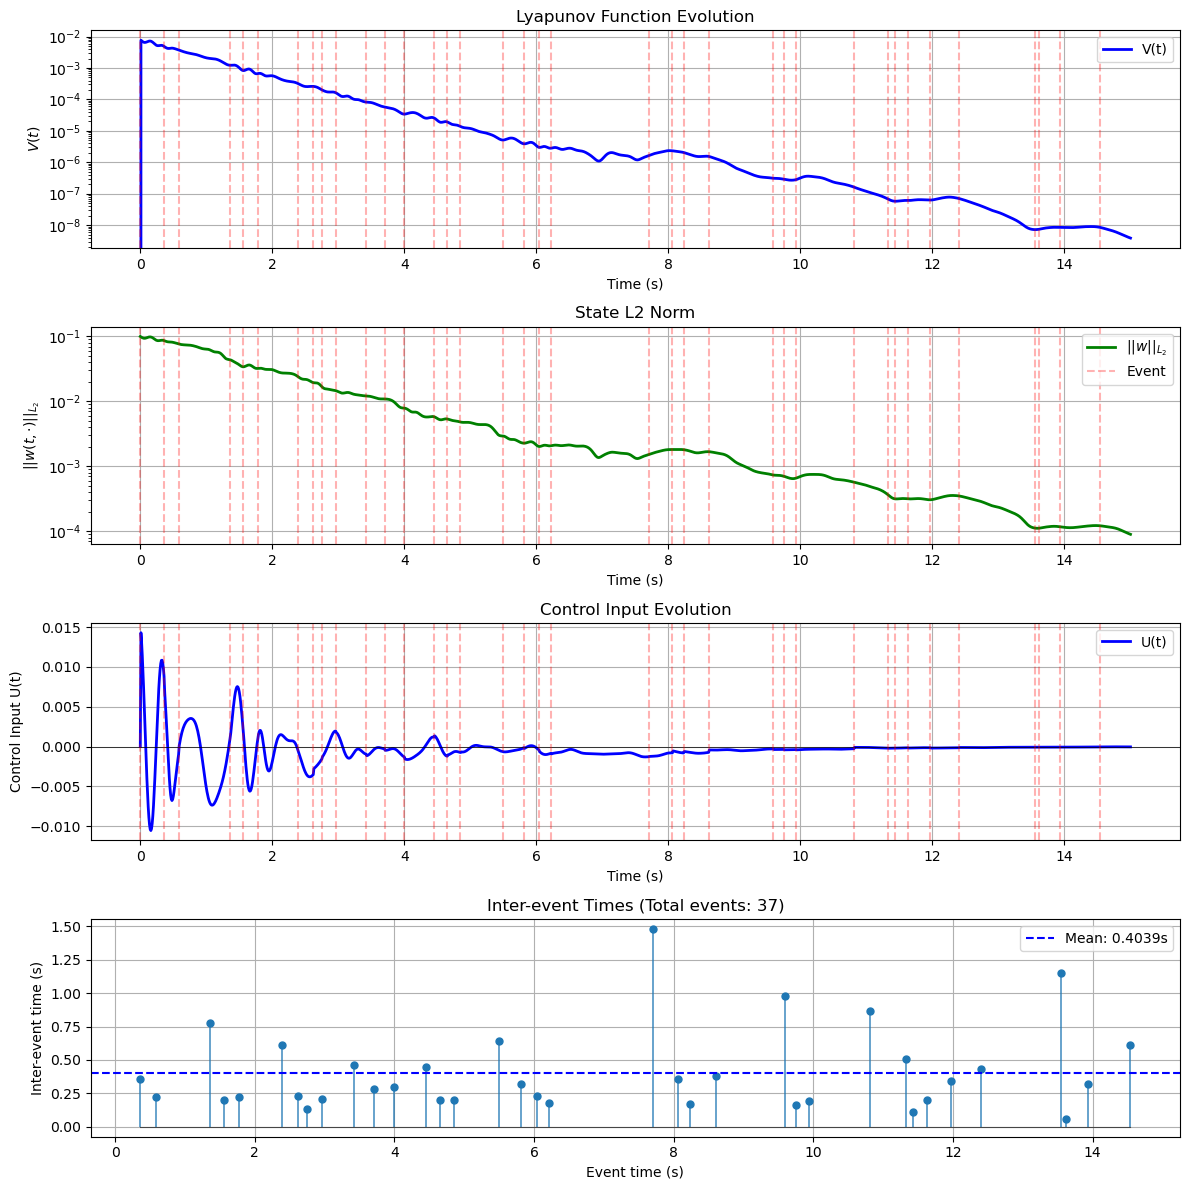


Event statistics:
  Min inter-event: 0.0600s
  Max inter-event: 1.4800s
  Mean inter-event: 0.4039s
  Total events: 37

Control input statistics:
  Max |U|: 0.014296
  Final U: -0.000041


In [17]:
# Extract u and v
u_log = x_log_all[:, :sys.N]
v_log = x_log_all[:, sys.N:2*sys.N]

# Compute state L2 norm
norm_log = np.sqrt(np.sum(u_log**2 + v_log**2, axis=1) * sys.Delta)

# Plots
fig, axes = plt.subplots(4, 1, figsize=(12, 12))

# 1. Lyapunov function
axes[0].semilogy(sys.Tspan, V_log, 'b-', linewidth=2, label='V(t)')
for et in event_times:
    axes[0].axvline(x=et, color='r', linestyle='--', alpha=0.3)
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel(r'$V(t)$')
axes[0].set_title('Lyapunov Function Evolution')
axes[0].grid(True)
axes[0].legend()

# 2. L2 norm
axes[1].semilogy(sys.Tspan, norm_log, 'g-', linewidth=2, label=r'$||w||_{L_2}$')
for et in event_times:
    axes[1].axvline(x=et, color='r', linestyle='--', alpha=0.3, label='Event' if et == event_times[0] else '')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel(r'$||w(t,·)||_{L_2}$')
axes[1].set_title('State L2 Norm')
axes[1].grid(True)
axes[1].legend()

# 3. Control input
axes[2].plot(sys.Tspan, U_log, 'b-', linewidth=2, label='U(t)')
axes[2].axhline(y=0, color='k', linestyle='-', linewidth=0.5)
for et in event_times:
    axes[2].axvline(x=et, color='r', linestyle='--', alpha=0.3)
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Control Input U(t)')
axes[2].set_title('Control Input Evolution')
axes[2].grid(True)
axes[2].legend()

# 4. Event timing (classic stem plot)
event_intervals = np.diff(event_times)
axes[3].set_xlabel('Event time (s)')
axes[3].set_ylabel('Inter-event time (s)')
axes[3].set_title(f'Inter-event Times (Total events: {num_events})')
axes[3].grid(True)

if len(event_intervals) > 0:
    event_times_mid = event_times[1:]

    markerline, stemlines, baseline = axes[3].stem(
        event_times_mid, event_intervals, linefmt='C0-', markerfmt='C0o', basefmt='k-'
    )
    plt.setp(stemlines, linewidth=1.2, alpha=0.8)
    plt.setp(markerline, markersize=5)
    plt.setp(baseline, linewidth=0.8, alpha=0.6)

    axes[3].axhline(y=np.mean(event_intervals), color='b', linestyle='--',
                    label=f'Mean: {np.mean(event_intervals):.4f}s')
    axes[3].legend()
else:
    axes[3].text(0.5, 0.5, 'No inter-event data', transform=axes[3].transAxes,
                 ha='center', va='center')

plt.tight_layout()
plt.show()

print("\nEvent statistics:")
print(f"  Min inter-event: {np.min(event_intervals):.4f}s")
print(f"  Max inter-event: {np.max(event_intervals):.4f}s")
print(f"  Mean inter-event: {np.mean(event_intervals):.4f}s")
print(f"  Total events: {num_events}")
print("\nControl input statistics:")
print(f"  Max |U|: {np.max(np.abs(U_log)):.6f}")
print(f"  Final U: {U_log[-1]:.6f}")

## 3D Visualization of State Evolution

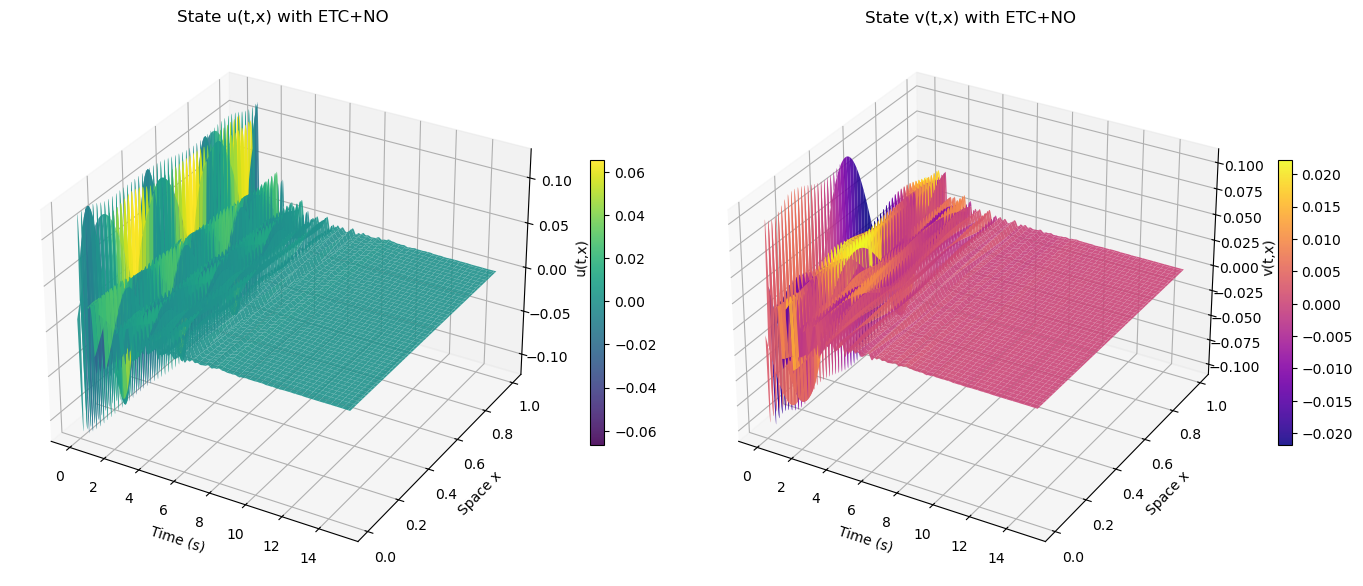

In [18]:
# Create grids
T_mesh, X_mesh = np.meshgrid(sys.Tspan, sys.xspanT)

fig = plt.figure(figsize=(14, 6))

# u(t,x)
ax1 = fig.add_subplot(121, projection='3d')
surf1 = ax1.plot_surface(T_mesh, X_mesh, u_log.T, cmap='viridis', 
                          edgecolor='none', alpha=0.9)
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Space x')
ax1.set_zlabel('u(t,x)')
ax1.set_title('State u(t,x) with ETC+NO')
fig.colorbar(surf1, ax=ax1, shrink=0.5)

# v(t,x)
ax2 = fig.add_subplot(122, projection='3d')
surf2 = ax2.plot_surface(T_mesh, X_mesh, v_log.T, cmap='plasma', 
                          edgecolor='none', alpha=0.9)
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Space x')
ax2.set_zlabel('v(t,x)')
ax2.set_title('State v(t,x) with ETC+NO')
fig.colorbar(surf2, ax=ax2, shrink=0.5)

plt.tight_layout()
plt.savefig('state_evolution_3d.png', dpi=150, bbox_inches='tight')
plt.show()

## Save results

In [19]:
# Save results
# Ensure threshold is saved for easier post-processing
threshold = nu_param * R_L * V_log

results = {
    'u_log': u_log,
    'v_log': v_log,
    'V_log': V_log,
    'U_log': U_log,
    'event_times': np.array(event_times),
    'norm_log': norm_log,
    'error_log': error_log,
    'threshold': threshold,
    'Tspan': sys.Tspan,
    'xspanT': sys.xspanT,
    'num_events': num_events,
    # 'train_loss_history': train_loss_history,
    # 'val_loss_history': val_loss_history
}

np.savez('etc_lyapunov_with_no_results.npz', **results)
print("Simulation results saved to etc_lyapunov_with_no_results.npz")

# # Save individual arrays for convenience
# # np.save('u_log_etc_no.npy', u_log)
# # np.save('v_log_etc_no.npy', v_log)
# # np.save('event_times_etc_no.npy', np.array(event_times))
# # np.save('V_log_etc_no.npy', V_log)

# print("Individual arrays saved")

Simulation results saved to etc_lyapunov_with_no_results.npz


Runtime comparison over 100 runs:
  Neural Operator: avg=1.08 ms, std=0.11 ms
  Exact Solver  : avg=210.25 ms, std=3.72 ms


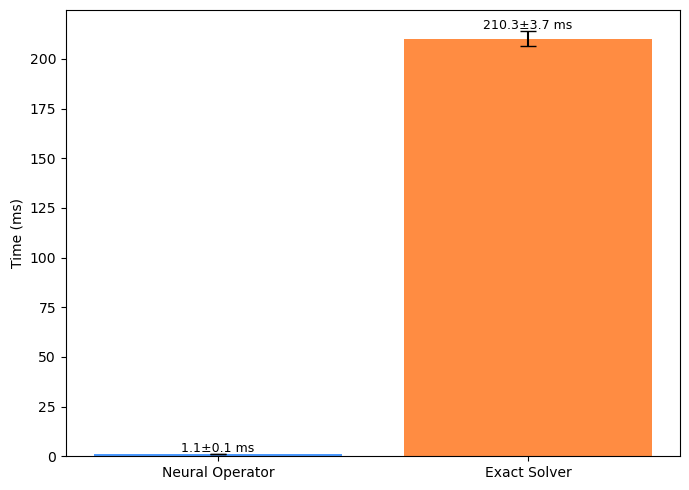

In [20]:
# Compare runtime: Neural Operator vs Exact Solver (average over 100 runs)
import time

# Prepare 100 random event times in [0, sys.T]
np.random.seed(7)
t_tests = np.random.uniform(0.0, sys.T, size=100)

# Warm-up to avoid first-call overhead skew
_ = predict_kernels_with_no(0.0, sys.N_g, fun, q_val, model_no, device, trunk_coords, use_nn=True)
_ = predict_kernels_with_no(0.0, sys.N_g, fun, q_val, model_no, device, trunk_coords, use_nn=False)

# Measure NO timings
no_times = []
for t_event in t_tests:
    t0 = time.perf_counter()
    Kuu_no, Kuv_no, Kvu_no, Kvv_no = predict_kernels_with_no(t_event, sys.N_g, fun, q_val, model_no, device, trunk_coords, use_nn=True)
    t1 = time.perf_counter()
    no_times.append(t1 - t0)

# Measure Exact solver timings
exact_times = []
for t_event in t_tests:
    t0 = time.perf_counter()
    Kuu_ex, Kuv_ex, Kvu_ex, Kvv_ex = predict_kernels_with_no(t_event, sys.N_g, fun, q_val, model_no, device, trunk_coords, use_nn=False)
    t1 = time.perf_counter()
    exact_times.append(t1 - t0)

no_avg = float(np.mean(no_times))
no_std = float(np.std(no_times))
ex_avg = float(np.mean(exact_times))
ex_std = float(np.std(exact_times))

print("Runtime comparison over 100 runs:")
print(f"  Neural Operator: avg={no_avg*1000:.2f} ms, std={no_std*1000:.2f} ms")
print(f"  Exact Solver  : avg={ex_avg*1000:.2f} ms, std={ex_std*1000:.2f} ms")

# Optional bar chart
import matplotlib.pyplot as plt
labels = ['Neural Operator', 'Exact Solver']
means = [no_avg*1000, ex_avg*1000]
errs = [no_std*1000, ex_std*1000]

fig, ax = plt.subplots(figsize=(7,5))
ax.bar(labels, means, yerr=errs, capsize=6, color=['#4C9AFF','#FF8C42'])
ax.set_ylabel('Time (ms)')
# ax.set_title('Kernel Prediction Runtime (100-run average)')
for i, m in enumerate(means):
    ax.text(i, m + errs[i] + 1.0, f"{m:.1f}±{errs[i]:.1f} ms", ha='center', fontsize=9)
plt.tight_layout()

plt.savefig('kernel_prediction_runtime_comparison.pdf', dpi=150, bbox_inches='tight')
plt.show()

## Visualize the Event-Triggering Condition

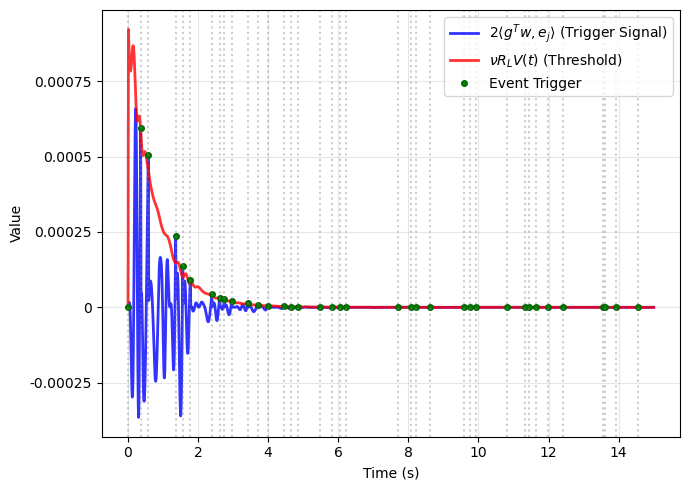

Total time steps violating threshold (trigger condition true): 36
Total events: 37; Event times: [0.0, 0.36, 0.58, 1.36, 1.56, 1.78, 2.39, 2.62, 2.75, 2.96, 3.42, 3.7, 4.0, 4.45, 4.65, 4.8500000000000005, 5.49, 5.8100000000000005, 6.04, 6.22, 7.7, 8.06, 8.23, 8.61, 9.59, 9.75, 9.94, 10.81, 11.32, 11.43, 11.63, 11.97, 12.4, 13.55, 13.61, 13.93, 14.540000000000001]
Mean inter-event time: 0.4039 s


In [21]:
# Visualize Event-Triggering Condition: 2⟨g w, e_j⟩ vs ν R_L V(t)
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

trigger_signal = error_log  # 2⟨g w, e_j⟩ over time
threshold = nu_param * R_L * V_log  # ν R_L V(t)

# Single plot (no subplots) to avoid figure.plot error
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(sys.Tspan, trigger_signal,  'b-', linewidth=2, label=r'$2\langle g^T w, e_j \rangle$ (Trigger Signal)', alpha=0.8)
ax.plot(sys.Tspan, threshold, 'r-', linewidth=2, label=r'$\nu R_L V(t)$ (Threshold)', alpha=0.8)

# Mark event times
for et in event_times:
    idx = np.argmin(np.abs(sys.Tspan - et))
    ax.plot(et, trigger_signal[idx], 'go', markersize=4, 
            markeredgecolor='darkgreen', markeredgewidth=1, 
            label='Event Trigger' if et == event_times[1] else '')
    ax.axvline(et, color='gray', linestyle=':', alpha=0.4, linewidth=1.5)

# ax.set_title('Event-Triggering Condition Over Time')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Value')
ax.legend()
ax.grid(True, alpha=0.3)

# Make y-axis labels concise
ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune='both'))
ax.yaxis.set_major_formatter(FormatStrFormatter('%.2g'))

plt.tight_layout()
plt.show()

# Print basic stats
trigger_count = int(np.sum(trigger_signal > threshold))
print(f"Total time steps violating threshold (trigger condition true): {trigger_count}")
print(f"Total events: {len(event_times)}; Event times: {event_times}")
if len(event_times) > 1:
    event_intervals = np.diff(event_times)
    print(f"Mean inter-event time: {np.mean(event_intervals):.4f} s")
